In [59]:
import pandas as pd
import seaborn as sbn
import numpy as np
import ast
from shapely.geometry import Polygon, Point
import matplotlib.pyplot as plt

# Mandatory 2 – Predikere om et skudd blir mål (StatsBomb, Barcelona i Messi-årene)

## 1. Mål med notebooken
Målet er å bygge en klassifikasjonsmodell som, ut fra informasjon om selve skuddsituasjonen, predikerer om et skudd ender i **mål** eller **ikke mål**. Datasettet består av **alle skudd i La Liga-kamper der Barcelona deltok** i Messi-årene i tillegg til **en** helt stråelende kamp fra 1973/1974 sesogen hvor **legenden Johan Cruyff** skåret og vant **5-0** over real mardird i deres hjemme bane, både Barcelonas egne skudd og motstandernes. Hvilket lag som skyter er med som en feature (`team`).

Målvariabelen lages fra kolonnen `shot_outcome`:
- `1` = `Goal`
- `0` = alle andre utfall (redda, utenfor mål, i stolpen, blokkert osv.)

Features er det som er kjent *i øyeblikket skuddet tas*: posisjon på banen, avstand og vinkel mot mål, kroppsdel, teknikk, spillsituasjon (`play_pattern`, `shot_type`), press, og hvordan keeper og forsvarere står plassert (`shot_freeze_frame`). Informasjon som først er kjent *etter* skuddet (f.eks. hvor ballen endte, `shot_end_location`) brukes ikke som feature fordi det er datalekkasje.

## 2. Data
**Kilde:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (åpent og gratis tilgjengelig event-data fra fotballkamper). Data er kreditert StatsBomb.

**Hvordan datasettet ble laget:**
1. Hentet oversikten over alle konkurranser og filtrerte på La Liga (18 sesonger).
2. Hentet alle kampene i La Liga og beholdt de der Barcelona spilte hjemme eller borte (525 kamper). Dette dekker sesongene 2004/05–2020/21, de årene Messi spilte for klubben, pluss én kamp fra 1973/74 (Real Madrid–Barcelona 0–5, Cruyff-tiden). Den kampen ble beholdt bevisst, siden den utgjør en svært liten del av datasettet og påvirker ikke resultatene.
3. Hentet alle hendelser (events) fra de 525 kampene og beholdt alle hendelser av typen `Shot`, uavhengig av hvilket lag som skjøt (Barcelona: 8 285 skudd, motstanderne: 4 700).
4. Valgte ut 24 relevante kolonner av de opprinnelige 119 (resten var tomme for skudd eller ikke relevante) og lagret resultatet som `barca_shots_events.csv`.

Datainnhentingen og filtreringen ble gjort over flere iterasjoner i et eget skript (`StatsBombEventsBarcelona`) og er ikke en del av denne innleveringen. Notebooken starter med den ferdige CSV-filen, slik at den kan kjøres uten nettverkstilgang.

**Størrelse:** 12 985 skudd, hvorav 1 775 mål (ca. 13,7 %).

## 3. Utfordring: ubalanserte klasser
Bare omtrent **1 av 7 skudd** blir mål. En modell som alltid svarer «ikke mål» får rundt 86 % *accuracy* uten å lære noe, så accuracy alene er misvisende her. Derfor legger jeg vekt på:
- precision, recall og F1 for målklassen, samt confusion matrix og precision-recall-kurver
- stratifisert deling og håndtering av ubalansen (f.eks. `class_weight`)
- `GroupKFold` på `match_id`, slik at skudd fra samme kamp ikke havner både i trening og test

## 4. Hva jeg vil lære av oppgaven
Oppgaven er også en mulighet til å jobbe grundig med metodene fra kurset:
- **Databehandling:** rensing, feature engineering (avstand, vinkel, freeze-frame-features), skalering, *power transformations* og *Principal Component Analysis (PCA)*
- **Pipelines** med `Pipeline` og `ColumnTransformer`, slik at all behandling skjer innenfor krysspvalideringen uten lekkasje
- **Automatisk hyperparameter-tuning** (og tuning av behandlingsvalg) og **kryssvalidering**
- **Modeller:** to baseline-modeller, tre avanserte modeller (bl.a. *bagging* og *boosting*) og til slutt et **kunstig nevralt nettverk (ANN)**
- **Evaluering** og sammenligning av alle modellene, også mot StatsBombs egen xG-modell (`shot_statsbomb_xg`) som ekstern referanse

## 5. Oversikt over notebooken
1. Innlasting og første inspeksjon
2. Databehandling og feature engineering
3. Utforskende dataanalyse (EDA) 
4. Baseline-modeller
5. Avanserte modeller og tuning
6. ANN
7. Evaluering og sammenligning
8. Konklusjon og begrensninger

In [3]:
barcelona_shots = pd.read_csv("data\\barcelona_shots_events.csv")

In [4]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [5]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 47.8, 0.0]",NaN,"[{'location': [91.6, 30.4], 'player': {'id': 5...",True,NaN,0.200969,Normal,Open Play,Off T
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,NaN,NaN,Right Foot,NaN,"[115.8, 42.1, 0.0]",True,"[{'location': [97.2, 35.3], 'player': {'id': 2...",NaN,NaN,0.096384,Normal,Open Play,Saved
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,NaN,NaN,Left Foot,NaN,"[120.0, 50.6, 0.0]",True,"[{'location': [104.3, 36.7], 'player': {'id': ...",NaN,NaN,0.098879,Normal,Open Play,Off T
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,NaN,NaN,Left Foot,NaN,"[119.8, 37.6]",NaN,"[{'location': [114.1, 43.8], 'player': {'id': ...",NaN,NaN,0.078938,Normal,Free Kick,Blocked
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.7, 0.0]",NaN,"[{'location': [108.6, 55.2], 'player': {'id': ...",True,True,0.976192,Normal,Open Play,Goal


In [6]:
barcelona_shots[barcelona_shots["player"] == "Johan Cruyff"]

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome
12967,3888713,Barcelona,Johan Cruyff,39713.0,34,57,1,Center Forward,"[108.0, 43.2]",0.872205,Regular Play,NaN,NaN,Left Foot,NaN,"[120.0, 40.5, 0.0]",NaN,"[{'location': [109.7, 38.6], 'player': {'id': ...",NaN,NaN,0.578706,Normal,Open Play,Goal
12973,3888713,Barcelona,Johan Cruyff,39713.0,52,33,2,Center Forward,"[98.3, 30.9]",1.391505,From Counter,NaN,NaN,Right Foot,NaN,"[120.0, 45.2, 6.7]",NaN,"[{'location': [97.6, 29.0], 'player': {'id': 3...",NaN,NaN,0.053107,Normal,Open Play,Off T
12975,3888713,Barcelona,Johan Cruyff,39713.0,57,14,2,Center Forward,"[98.3, 23.8]",2.020851,From Throw In,NaN,NaN,Right Foot,NaN,"[120.0, 52.9, 0.0]",NaN,"[{'location': [95.2, 40.2], 'player': {'id': 3...",NaN,NaN,0.021481,Half Volley,Open Play,Off T
12976,3888713,Barcelona,Johan Cruyff,39713.0,57,38,2,Center Forward,"[98.2, 42.2]",0.277758,Regular Play,NaN,NaN,Right Foot,NaN,"[101.7, 42.6]",NaN,"[{'location': [118.7, 40.6], 'player': {'id': ...",NaN,NaN,0.074925,Normal,Open Play,Blocked
12984,3888713,Barcelona,Johan Cruyff,39713.0,86,34,2,Center Forward,"[100.2, 49.9]",0.202476,From Throw In,NaN,NaN,Right Foot,NaN,"[103.1, 47.9]",NaN,"[{'location': [88.5, 63.6], 'player': {'id': 3...",NaN,NaN,0.044297,Half Volley,Open Play,Blocked


In [7]:
barcelona_shots.dtypes

match_id                  int64
team                        str
player                      str
player_id               float64
minute                    int64
second                    int64
period                    int64
position                    str
location                    str
duration                float64
play_pattern                str
under_pressure           object
shot_follows_dribble     object
shot_body_part              str
shot_aerial_won          object
shot_end_location           str
shot_first_time          object
shot_freeze_frame           str
shot_one_on_one          object
shot_open_goal           object
shot_statsbomb_xg       float64
shot_technique              str
shot_type                   str
shot_outcome                str
dtype: object

### Datatyper
Her ser jeg hvilken datatype hver kolonne har.

- **Tall** (`int64`/`float64`): `match_id`, `minute`, `second`, `period`, `duration`, `shot_statsbomb_xg` og `player_id`. `player_id` er `float64` selv om det er et heltall, så den gjør jeg om til `int` senere.
- **Tekst** (`str`): `team`, `player`, `position`, `play_pattern`, `shot_body_part`, `shot_technique`, `shot_type` og `shot_outcome`. Tekstkategoriene må encodes til tall før modellene kan bruke dem.
- **Lister som tekst:** `location`, `shot_end_location` og `shot_freeze_frame` vises som `str` fordi dataene ligger i en CSV-fil. Listene ble til tekststrenger da filen ble lagret, og må gjøres om til ekte lister igjen.
- **`object`:** de seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) er `object` fordi de blander `True` og tomme verdier. De må ryddes opp.

In [8]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.010705
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
dtype: float64

### Manglende verdier
Her ser jeg andelen manglende verdier (0 = ingen mangler, 1 = alt mangler) i hver kolonne.

- **De fleste kolonnene er komplette** (0,0).
- **Flaggkolonnene har mange tomme verdier**: `shot_follows_dribble` (99,9 %), `shot_open_goal` (98,7 %), `shot_aerial_won` (94,2 %), `shot_one_on_one` (92,8 %), `under_pressure` (83,8 %) og `shot_first_time` (69,2 %). Dette er ikke ekte manglende data. StatsBomb fyller bare inn `True` når noe skjedde, så tom betyr «nei».
- **`shot_freeze_frame` mangler for 1,1 % av skuddene.** Det er de 139 straffesparkene, som ikke har noen freeze frame.

In [9]:
#Location 
# [ <gjør_noe_med_elementet> for element in <samling_av_elementer> if <betingelse> ]
#barcelona_shots["location"] = barcelona_shots["location"].apply(ast.literal_eval)

In [10]:
barcelona_shots["location"].isna().sum()

np.int64(0)

In [11]:
def converting_columns_to_list(column_name):
    barcelona_shots[column_name] = [ast.literal_eval(rad) if isinstance(rad, str)  
    else rad if isinstance(rad, list)
    else []
    for rad in barcelona_shots[column_name] ]

In [12]:
converting_columns_to_list("location")
converting_columns_to_list("shot_end_location")
converting_columns_to_list("shot_freeze_frame")

In [13]:
barcelona_shots.isna().mean()

match_id                0.000000
team                    0.000000
player                  0.000000
player_id               0.000000
minute                  0.000000
second                  0.000000
period                  0.000000
position                0.000000
location                0.000000
duration                0.000000
play_pattern            0.000000
under_pressure          0.837659
shot_follows_dribble    0.998999
shot_body_part          0.000000
shot_aerial_won         0.941625
shot_end_location       0.000000
shot_first_time         0.692337
shot_freeze_frame       0.000000
shot_one_on_one         0.928071
shot_open_goal          0.987062
shot_statsbomb_xg       0.000000
shot_technique          0.000000
shot_type               0.000000
shot_outcome            0.000000
dtype: float64

### Lister og manglende verdier i `location`-kolonnene
Kolonnene `location`, `shot_end_location` og `shot_freeze_frame` var lister som hadde blitt til tekst da dataene ble lagret som CSV. Jeg har derfor skrevet funksjonen `converting_columns_to_list`, som gjør teksten om til lister igjen. Funksjonen kan kjøres flere ganger uten å ødelegge dataene, og de 139 manglende freeze frames (straffer) blir til tomme lister `[]`.

Etter konverteringen mangler ingen verdier i disse tre kolonnene. Det betyr ikke at straffene har fått en freeze frame, men at den er en tom liste. Det tar jeg hensyn til når jeg lager features fra den senere.

In [14]:
flag_cols= ["under_pressure", "shot_follows_dribble", "shot_aerial_won", 
                 "shot_first_time", "shot_one_on_one", "shot_open_goal"]

In [15]:
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].fillna(value=False)
barcelona_shots[flag_cols] = barcelona_shots[flag_cols].astype(int)

In [16]:
barcelona_shots[flag_cols].dtypes

under_pressure          int64
shot_follows_dribble    int64
shot_aerial_won         int64
shot_first_time         int64
shot_one_on_one         int64
shot_open_goal          int64
dtype: object

In [17]:
barcelona_shots[flag_cols].sum()

under_pressure          2108
shot_follows_dribble      13
shot_aerial_won          758
shot_first_time         3995
shot_one_on_one          934
shot_open_goal           168
dtype: int64

### Flaggkolonnene til 0 og 1
De seks flaggkolonnene (`under_pressure`, `shot_follows_dribble`, `shot_aerial_won`, `shot_first_time`, `shot_one_on_one`, `shot_open_goal`) hadde bare `True` eller tomt, der tomt betyr «nei». Jeg fylte de tomme verdiene med `False` og gjorde `True`/`False` om til `1`/`0`. Dette er en enkel form for koding (encoding).

Etter konverteringen er alle seks kolonnene `int64`, og summene stemmer med antallet `True` før konverteringen: 2 108 skudd under press, 3 995 første-berøringsskudd, 934 en-mot-en, 758 hodeduellseire, 168 mot åpent mål og 13 etter dribling.

Flaggene er sjeldne, så de fleste verdiene er 0. `shot_follows_dribble` har bare 13 enere og vil sannsynligvis ikke bety mye for modellen.

In [18]:
barcelona_shots["location_x"] = barcelona_shots["location"].str[0]
barcelona_shots["location_y"] = barcelona_shots["location"].str[1]

In [19]:
#np.sqrt((120 - df['x'])**2 + (40 - df['y'])**2)
barcelona_shots["shot_distance_from_goal"] = np.sqrt((120- barcelona_shots["location_x"])**2 + (40 - barcelona_shots["location_y"])**2 )

In [20]:
barcelona_shots.head()
#scale_pos_weight i XGBoost eller bruke class_weight='balanced'

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851


In [21]:
#df['vinkel_senter'] = np.degrees(np.arctan2(np.abs(40 - df['y']), 120 - df['x']))
barcelona_shots["shot_angle"] = np.degrees(np.arctan2(np.abs(40- barcelona_shots["location_y"]), 120 - barcelona_shots["location_x"]))

In [22]:
teller = 8 * (120 - barcelona_shots['location_x'])
nevner = (120 - barcelona_shots['location_x'])**2 + (36 - barcelona_shots['location_y']) * (44 - barcelona_shots['location_y'])

barcelona_shots['shot_angle_visual'] = np.degrees(np.arctan2(teller, nevner))

In [23]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287


### Posisjonsfeatures: avstand og to vinkler
Posisjonen er gitt som `x` (banens lengde, 0–120) og `y` (bredden, 0–80). Begge lag angriper mot x = 120, målmidten ligger på (120, 40), og stolpene står på y = 36 og y = 44. Fra `x` og `y` har jeg laget tre features:

- **`shot_distance_from_goal`**: faktisk avstand til målmidten, regnet ut med Pythagoras: √((120 − x)² + (40 − y)²). Kort avstand gir normalt større sjanse for mål.
- **`shoot_angle`**: vinkelen bort fra midtlinjen mot mål, regnet ut med `arctan2`. 0° betyr rett foran mål, og 90° betyr helt ute ved dødlinjen. Den sier hvor skeivt skuddet er tatt, men ikke hvor stort mål skytteren har å sikte på.
- **`shot_angle_visual`**: åpningsvinkelen, altså vinkelen mellom linjene fra skytteren til de to stolpene. Den sier hvor stor del av målet skytteren ser. Formelen er hentet fra [Soccermatics, «The geometry of shooting»](https://soccermatics.readthedocs.io/en/latest/lesson2/GeometryOfShooting.html) (David Sumpter) og tilpasset StatsBombs koordinater, der målet er 8 enheter bredt: `8·dx / (dx² + (36 − y)(44 − y))`, med `dx = 120 − x`. 

**Forskjellen på de to vinklene:** Et skudd rett foran mål, men langt ute, har `shoot_angle` = 0°, men en liten åpning (ca. 15°). Et skudd fra siden i boksen har stor `shoot_angle` (46°), men en åpning på ca. 19°. Helt ute ved dødlinjen er `shoot_angle` nesten 90°, men åpningen bare noen få grader. Åpningsvinkelen er en ikke-lineær kombinasjon av posisjonen som enkle modeller (som logistisk regresjon) vanskelig kan lære selv. Jeg har derfor laget den på forhånd og vil sammenligne hvor mye hver av dem betyr for modellene senere.

In [24]:
barcelona_shots.dtypes

match_id                     int64
team                           str
player                         str
player_id                  float64
minute                       int64
second                       int64
period                       int64
position                       str
location                    object
duration                   float64
play_pattern                   str
under_pressure               int64
shot_follows_dribble         int64
shot_body_part                 str
shot_aerial_won              int64
shot_end_location           object
shot_first_time              int64
shot_freeze_frame           object
shot_one_on_one              int64
shot_open_goal               int64
shot_statsbomb_xg          float64
shot_technique                 str
shot_type                      str
shot_outcome                   str
location_x                 float64
location_y                 float64
shot_distance_from_goal    float64
shot_angle                 float64
shot_angle_visual   

In [25]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [26]:
barcelona_shots["keeper_x"] =barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False][0][0] 
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [27]:
barcelona_shots["keeper_y"] = barcelona_shots["shot_freeze_frame"].apply(lambda x: 
                                           [spiller.get("location") for spiller in x if isinstance(spiller, dict) and spiller.get("position")["name"] == "Goalkeeper" and spiller.get("teammate") == False ][0][1]
                                           if isinstance(x, list) and len([s for s in x if isinstance(s, dict) and s.get("position")["name"] == "Goalkeeper" and s.get("teammate") == False]) > 0 else None) 

In [28]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3


In [29]:
def pythagoras(x1, y1, x2, y2):
   return np.sqrt(((x2-x1)**2) + ((y2-y1)**2))

In [30]:
def distance_column_maker(dataset, columnx1, columny1,  columnx2,columny2, newcolumn):
   dataset[newcolumn] = pythagoras(dataset[columnx1], dataset[columny1], dataset[columnx2], dataset[columny2])
      

In [31]:
distance_column_maker(barcelona_shots, columnx1="location_x", columny1="location_y", columnx2="keeper_x", columny2="keeper_y", newcolumn="distance_between_shooter_and_keeper")

In [32]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987


In [33]:
barcelona_shots.isna().sum()

match_id                                 0
team                                     0
player                                   0
player_id                                0
minute                                   0
second                                   0
period                                   0
position                                 0
location                                 0
duration                                 0
play_pattern                             0
under_pressure                           0
shot_follows_dribble                     0
shot_body_part                           0
shot_aerial_won                          0
shot_end_location                        0
shot_first_time                          0
shot_freeze_frame                        0
shot_one_on_one                          0
shot_open_goal                           0
shot_statsbomb_xg                        0
shot_technique                           0
shot_type                                0
shot_outcom

In [34]:
barcelona_shots.loc[148, ["keeper_x", "keeper_y"]]

keeper_x    117.5
keeper_y     40.7
Name: 148, dtype: float64

### Features fra `shot_freeze_frame`
Kolonnen `shot_freeze_frame` er spesiell fordi den gir et «frossent bilde» av banen i det øyeblikket skuddet ble tatt. For hvert skudd får vi en liste over spillerne som var synlige, med posisjon, rolle (f.eks. keeper eller back) og om de er medspiller eller motstander. Listen er ikke et tall, så modellene kan ikke bruke den direkte. Jeg gjør den derfor om til features med fast betydning.

I feature engineering er målet å gi modellen så mye relevant informasjon om hendelsen som mulig. Jeg mener at gode features ofte er minst like viktig som tuning av selve modellen. Jeg har derfor valgt fire features fra frysebildet:

1. **Avstand mellom skytteren og keeperen**
2. **Avstand mellom keeperen og målmidten**
3. **Antall motstandere rundt skytteren**, talt i tre ringer med ulik radius (hvor kompakt forsvaret står)
4. **Antall motstandere i trekanten** mellom skytteren og de to stolpene (altså de som står i skuddlinjen)

Jeg lager ikke én kolonne per spiller. Antall spillere varierer fra skudd til skudd, og rekkefølgen i listen er tilfeldig, så slike kolonner ville vært nesten tomme og uten fast betydning.

#### Feature 1: avstand mellom skytteren og keeperen
Jeg gjorde dette i tre steg:
1. **Fant keeperen i hver rad.** Jeg gikk gjennom spillerne i frysebildet og valgte den som har posisjonen `Goalkeeper` og som *ikke* er medspiller. Sjekken på medspiller er viktig, for i noen skudd er egen keeper også synlig i bildet, og da ville jeg fått feil keeper.
2. **Hentet ut keeperens `x` og `y`** i to nye kolonner, `keeper_x` og `keeper_y`.
3. **Regnet ut avstanden** mellom skytteren og keeperen med Pythagoras' setning og la den i kolonnen `distance_between_shooter_and_keeper`.

Jeg kontrollerte at resultatet stemmer ved å regne for hånd på første skudd (skytter på (108,6, 28,0), keeper på (114,5, 33,8) gir ca. 8,27) og ved å teste på en rad der egen keeper står først i lista.

**Manglende verdier:** 151 skudd har ingen keeper. 139 er straffespark, som ikke har noe frysebilde, og 12 er skudd der motstanderens keeper ikke var synlig. Disse får `NaN` i alle keeperkolonnene. Det håndterer jeg senere i pipelinen (imputering eller en modell som takler `NaN`), slik at verdiene læres fra treningsdata alene.

In [35]:
barcelona_shots["distance_between_keeper_and_goal"]= pythagoras(barcelona_shots["keeper_x"], barcelona_shots["keeper_y"], 120, 40)

In [36]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372


### Feature 2: avstand mellom keeperen og målmidten

Hensikten med feature engineering er å gi modellene så mye relevant informasjon som mulig, slik at mønstrene blir lette å fange. Denne featuren måler avstanden fra keeperen til målmidten (120, 40), altså hvor langt keeperen står fra sitt eget mål. Den regnes ut med samme avstandsformel som før.

**Hva tilbyr den?** Sammen med `distance_between_shooter_and_keeper` gir den et bilde av keeperens plassering i tre trekk:

- `distance_between_shooter_and_keeper` sier hvor langt det er mellom keeper og skytter.
- `distance_between_keeper_and_goal` sier hvor langt ute keeperen står fra målet.
- Sammen viser de om keeperen står dypt på streken, har kommet ut for å korte ned vinkelen, eller er ute av posisjon.

En keeper som står langt ute har dekket mer av vinkelen, men kan bli omgått eller lobbet. Modellene kan lære hvilke av disse situasjonene som oftest ender i mål.

Som for første keeper-feature mangler verdien når keeperen ikke er synlig i freeze frame, og for straffespark (til sammen 151 rader). Dette skal da håndteres i pipelinen senere.

In [37]:
barcelona_shots["shot_freeze_frame"][0]

[{'location': [91.6, 30.4],
  'player': {'id': 5487, 'name': 'Antoine Griezmann'},
  'position': {'id': 23, 'name': 'Center Forward'},
  'teammate': True},
 {'location': [99.2, 43.8],
  'player': {'id': 5503, 'name': 'Lionel Andrés Messi Cuccittini'},
  'position': {'id': 19, 'name': 'Center Attacking Midfield'},
  'teammate': True},
 {'location': [96.7, 53.3],
  'player': {'id': 6612, 'name': 'Rubén Duarte Sánchez'},
  'position': {'id': 6, 'name': 'Left Back'},
  'teammate': False},
 {'location': [95.7, 33.4],
  'player': {'id': 6615, 'name': 'Víctor Laguardia Cisneros'},
  'position': {'id': 3, 'name': 'Right Center Back'},
  'teammate': False},
 {'location': [103.8, 40.0],
  'player': {'id': 3093, 'name': 'Florian Grégoire Claude Lejeune'},
  'position': {'id': 5, 'name': 'Left Center Back'},
  'teammate': False},
 {'location': [106.0, 29.2],
  'player': {'id': 6923, 'name': 'Joaquín Navarro Jiménez'},
  'position': {'id': 2, 'name': 'Right Back'},
  'teammate': False},
 {'location

In [38]:
frame = barcelona_shots["shot_freeze_frame"]
for player in frame[0]:
    print(player.get("position")["name"])

Center Forward
Center Attacking Midfield
Left Back
Right Center Back
Left Center Back
Right Back
Goalkeeper


In [39]:
def find_opponents(freeze_frame):
    """Gir en liste med [x, y] for motstanderne, uten keeper."""
    if not isinstance(freeze_frame, list) or len(freeze_frame) == 0:
        return None

    opponents = []
    for player in freeze_frame:
        is_opponent = player.get("teammate") == False
        is_keeper = player["position"]["name"] == "Goalkeeper"
        if is_opponent and not is_keeper:
            opponents.append(player["location"])
    return opponents


def count_in_ring(row, inner, outer):
    """Teller motstandere med avstand større enn inner og opptil outer fra skytteren."""
    opponents = find_opponents(row["shot_freeze_frame"])
    if opponents is None:
        return np.nan

    count = 0
    for opp_x, opp_y in opponents:
        distance = pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
        if inner < distance <= outer:
            count += 1
    return count


barcelona_shots["opponents_within_2_5_yards"] = barcelona_shots.apply(count_in_ring, axis=1, inner=0,   outer=2.5)
barcelona_shots["opponents_2_5_to_5_yards"]   = barcelona_shots.apply(count_in_ring, axis=1, inner=2.5, outer=5)
barcelona_shots["opponents_5_to_10_yards"]    = barcelona_shots.apply(count_in_ring, axis=1, inner=5,   outer=10)

ring_features = ["opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards"]

In [40]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': [101.4, 54.2], 'player': {'id': ...",1,0,0.203073,Normal,Open Play,Off T,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': [110.5, 42.7], 'player': {'id': ...",0,0,0.095015,Normal,Free Kick,Blocked,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': [95.2, 41.6], 'player': {'id': 3...",0,0,0.017764,Normal,Free Kick,Off T,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': [105.4, 33.3], 'player': {'id': ...",0,0,0.112452,Normal,Open Play,Saved,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,Regular Play,0,0,Left Foot,0,"[118.2, 35.8, 1.3]",0,"[{'location': [106.2, 32.9], 'player': {'id': ...",1,0,0.054103,Normal,Open Play,Saved,113.3,26.1,15.430489,64.265264,13.567913,118.2,35.8,10.867382,4.569464,1.0,0.0,3.0


### Feature 3: motstandere rundt skytteren (tre ringer)

Disse tre featurene teller hvor mange motstandere som står i tre ikke-overlappende ringer rundt skytteren: 0–2,5, 2,5–5 og 5–10 yards. Keeperen er ikke med, siden han har egne features. Hver motstander telles i bare én ring.

**Hva tilbyr de?** De sier hvor kompakt forsvaret står rundt skytteren. Hypotesen er at et skudd med mange motstandere tett på har lavere sannsynlighet for å bli mål, fordi skytteren har mindre tid og plass, og skuddet oftere blir blokkert. Er det få motstandere i nærheten, er det motsatt. Modellen får dermed et bilde av situasjonen, ikke bare av posisjonen på banen. Dette er en hypotese som modellene skal teste, ikke noe vi vet på forhånd.

**Håndtering av manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes men ingen motstandere er synlige, telles ringene som 0. `NaN` håndteres senere i pipelinen.

**Ablasjonsstudie:** Disse featurene samles i listen `ring_features`, fordi jeg senere vil gjøre en ablasjonsstudie. Jeg trener samme modell med og uten gruppen, med samme CV-folder, og sammenligner gjennomsnitt og standardavvik i F1 og PR-AUC. Blir modellen dårligere uten ringene, tilfører de reell informasjon. Er den like god eller bedre, er de overflødige.

In [41]:
barcelona_shots[ring_features].isna().sum()    # skal være 139 per kolonne (straffene)

opponents_within_2_5_yards    139
opponents_2_5_to_5_yards      139
opponents_5_to_10_yards       139
dtype: int64

In [42]:
barcelona_shots[ring_features].describe()

,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards
count,12846.000000,12846.000000,12846.000000
mean,0.671960,0.881208,1.846178
std,0.759814,0.921637,1.373498
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,3.000000
max,5.000000,6.000000,10.000000


In [43]:
def nearest_opponent_distance(row):
    opponents = find_opponents(row["shot_freeze_frame"])
    if not opponents:                      # None (straffe) eller tom liste
        return np.nan
    return min(pythagoras(row["location_x"], row["location_y"], opp_x, opp_y)
               for opp_x, opp_y in opponents)


barcelona_shots["distance_to_nearest_opponent"] = barcelona_shots.apply(nearest_opponent_distance, axis=1)

In [44]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307


### Feature 4: avstand til nærmeste motstander

Denne featuren måler avstanden fra skytteren til den motstanderen som står nærmest. Keeperen er ikke med, siden han har egne features. Avstanden regnes ut med samme avstandsformel som tidligere, og vi tar minimumsverdien av alle motstandernes avstander.

**Hva tilbyr den?** Ringene i feature 3 gir bare en grov tellinger (hvor mange som står innenfor 2,5, 5 og 10 yards). Nærmeste motstander gir en kontinuerlig verdi som sier hvor mye press skytteren er under akkurat nå. Modellen kan dermed skille et skudd med en forsvarer 0,3 yards unna fra et med en forsvarer 2,4 yards unna, selv om begge ligger i samme ring.

Featuren overlapper delvis med ringene, spesielt de to innerste. Den måler også noe annet enn en eventuell trekant-feature, som viser om skuddlinjen er dekket. Nærmeste motstander sier noe om press, uavhengig av hvor motstanderen står i forhold til målet.

**Manglende verdier:** Skudd uten freeze frame (139 straffer) og skudd der ingen motstandere er synlige (29 rader) får `NaN`, til sammen 168 rader. Det finnes ingen nærmeste motstander i disse tilfellene, så `NaN` er riktig. Håndteres senere i pipelinen.

**Ablasjonsstudie:** Featuren ligger i en egen gruppe, `pressure_features`, slik at vi kan teste om den tilfører noe utover ringene. Hvis modellen ikke blir dårligere uten den, kan den fjernes.

In [45]:
def thresome_maker(player_x, player_y):
    h_stolpe_x, h_stolpe_y = 120, 44
    v_stolpe_x, v_stolpe_y = 120, 36

    koordinatene = [(player_x, player_y), (h_stolpe_x, h_stolpe_y), (v_stolpe_x, v_stolpe_y)]
    trekant = Polygon(koordinatene)

    return trekant 

def opponents_counter(date_frame):
    opponents_players = find_opponents(date_frame["shot_freeze_frame"])
    if opponents_players is None:
        return np.nan
    triangle = thresome_maker(date_frame["location_x"] , date_frame["location_y"])
    player_counter = 0

    for x, y in opponents_players:
        if triangle.covers(Point(x, y)):
            player_counter += 1
    return player_counter


    
        

In [46]:
barcelona_shots["opponents_in_shot_triangle"] = barcelona_shots.apply(opponents_counter, axis=1)

In [47]:
triangle_features= ["opponents_in_shot_triangle"]

In [48]:
barcelona_shots.head(10)

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0
5,3773386,Barcelona,Frenkie de Jong,8118.0,35,25,1,Left Defensive Midfield,"[113.1, 39.3]",0.155746,From Free Kick,1,0,Head,1,"[120.0, 38.5, 4.9]",0,"[{'location': [101.4, 54.2], 'player': {'id': ...",1,0,0.203073,Normal,Open Play,Off T,113.1,39.3,6.935416,5.792796,59.821068,118.8,39.9,5.731492,1.204159,1.0,1.0,1.0,0.640312,0.0
6,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,42,34,1,Center Attacking Midfield,"[101.3, 41.6]",0.236524,From Free Kick,0,0,Left Foot,0,"[110.5, 39.5]",0,"[{'location': [110.5, 42.7], 'player': {'id': ...",0,0,0.095015,Normal,Free Kick,Blocked,101.3,41.6,18.768324,4.890402,23.984619,119.1,38.6,18.051039,1.664332,0.0,0.0,8.0,9.265528,6.0
7,3773386,Deportivo Alavés,Florian Grégoire Claude Lejeune,3093.0,44,47,1,Left Center Back,"[84.7, 42.1]",1.196929,From Free Kick,0,0,Right Foot,0,"[120.0, 46.4, 5.6]",0,"[{'location': [95.2, 41.6], 'player': {'id': 3...",0,0,0.017764,Normal,Free Kick,Off T,84.7,42.1,35.362409,3.404518,12.885083,119.0,40.0,34.364226,1.000000,0.0,1.0,0.0,4.494441,2.0
8,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,45,16,1,Center Attacking Midfield,"[105.3, 32.9]",0.728686,From Goal Kick,1,0,Left Foot,0,"[118.3, 37.0, 0.0]",1,"[{'location': [105.4, 33.3], 'player': {'id': ...",0,0,0.112452,Normal,Open Play,Saved,105.3,32.9,16.324828,25.780227,25.148228,118.3,37.6,13.823531,2.941088,1.0,1.0,4.0,0.412311,0.0
9,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,47,47,2,Center Attacking Midfield,"[113.3, 26.1]",0.350130,Regular Play,0,0,Left Foot,0,"[118.2, 35.8, 1.3]",0,"[{'location': [106.2, 32.9], 'player': {'id': ...",1,0,0.054103,Normal,Open Play,Saved,113.3,26.1,15.430489,64.265264,13.567913,118.2,35.8,10.867382,4.5694

### Feature 5: antall motstandere i skuddtrekanten

Denne featuren teller hvor mange motstandere som står inne i trekanten mellom skytteren og målet. Trekanten har skytteren som spiss og de to stolpene, (120, 36) og (120, 44), som de to andre hjørnene. Motstandere i trekanten kan blokkere skuddlinjen. Keeperen er ikke med, siden han har egne features.

**Hva tilbyr den?** Ringene i feature 3 og nærmeste motstander i feature 4 sier noe om press rundt skytteren. Trekanten sier noe annet: hvor åpen veien mot mål er. En forsvarer som står rett ved siden av skytteren legger press på ham, men blokkerer ikke nødvendigvis skuddet. En forsvarer midt i trekanten gjør det. Modellen får dermed et mål på blokkering, som de andre featurene ikke fanger direkte.

**Hvordan den er laget:** Jeg brukte biblioteket [`shapely`](https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html), som er laget for geometri. Det brukes slik her:
- `Polygon` lager trekanten fra de tre hjørnene.
- `Point` lager et punkt av hver motstanders posisjon.
- `covers` sjekker om punktet ligger i trekanten, også om det ligger nøyaktig på kanten.

Funksjonen kjøres på hver rad med `.apply(..., axis=1)`. Dokumentasjon: <https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html>

**Manglende verdier:** Skudd uten freeze frame (139 straffer) får `NaN`. Hvis freeze frame finnes, men ingen motstandere står i trekanten, er verdien 0.

**Ablasjonsstudie:** Featuren legges i gruppen `triangle_features`, så vi kan teste om modellen blir dårligere uten den.

In [49]:
barcelona_shots["shot_outcome_target"] = (barcelona_shots["shot_outcome"] == "Goal").astype(int)

In [50]:
barcelona_shots["shot_outcome_target"].value_counts()

shot_outcome_target
0    11210
1     1775
Name: count, dtype: int64

### Målvariabel: binær klassifisering (mål / ikke mål)

Jeg lager målvariabelen `shot_outcome_target` fra `shot_outcome`:

- **1** hvis skuddet ble mål (`"Goal"`)
- **0** for alt annet (reddet, forbi målet, blokkert og så videre)

Jeg har valgt et **todelt klassifikasjonsproblem** i stedet for å forutsi hvert enkelt utfall. Målet mitt er å vite om jeg kan predikere om et skudd blir mål eller ikke. Jeg er ikke interessert i å skille mellom reddet, utenfor mål og blokkert. Et flerklasseproblem ville dessuten delt datasettet i flere mindre klasser, og det ville gjort modellene vanskeligere å trene og evaluere uten å svare bedre på spørsmålet jeg faktisk stiller.

Datasettet er skjevt fordelt: 1 775 mål (13,7 %) mot 11 210 skudd uten mål. Derfor bruker jeg presisjon, recall, F1 og PR-kurver sammen med accuracy, siden en modell som alltid sier «ikke mål» får over 86 % accuracy uten å lære noe.

`shot_outcome` skal senere fjernes fra featurene før trening, siden den inneholder selve fasiten.

In [51]:
barcelona_shots.head()

,match_id,team,player,player_id,minute,second,period,position,location,duration,play_pattern,under_pressure,shot_follows_dribble,shot_body_part,shot_aerial_won,shot_end_location,shot_first_time,shot_freeze_frame,shot_one_on_one,shot_open_goal,shot_statsbomb_xg,shot_technique,shot_type,shot_outcome,location_x,location_y,shot_distance_from_goal,shot_angle,shot_angle_visual,keeper_x,keeper_y,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle,shot_outcome_target
0,3773386,Barcelona,Anssumane Fati,30756.0,12,19,1,Left Wing,"[108.6, 28.0]",0.882096,From Throw In,0,0,Right Foot,0,"[120.0, 47.8, 0.0]",0,"[{'location': [91.6, 30.4], 'player': {'id': 5...",1,0,0.200969,Normal,Open Play,Off T,108.6,28.0,16.551737,46.468801,19.470701,114.5,33.8,8.273452,8.287943,0.0,1.0,0.0,2.863564,0.0,0
1,3773386,Deportivo Alavés,Edgar Antonio Méndez Ortega,26387.0,16,7,1,Right Midfield,"[103.6, 51.0]",0.446744,Regular Play,0,0,Right Foot,0,"[115.8, 42.1, 0.0]",1,"[{'location': [97.2, 35.3], 'player': {'id': 2...",0,0,0.096384,Normal,Open Play,Saved,103.6,51.0,19.747405,33.851010,19.332894,116.3,41.8,15.682155,4.114608,0.0,0.0,2.0,6.525335,0.0,0
2,3773386,Barcelona,Antoine Griezmann,5487.0,19,42,1,Center Forward,"[104.3, 33.9]",1.366058,From Throw In,0,0,Left Foot,0,"[120.0, 50.6, 0.0]",1,"[{'location': [104.3, 36.7], 'player': {'id': ...",0,0,0.098879,Normal,Open Play,Off T,104.3,33.9,16.843396,21.232892,25.135121,118.5,37.8,14.725828,2.662705,0.0,1.0,4.0,2.800000,1.0,0
3,3773386,Barcelona,Lionel Andrés Messi Cuccittini,5503.0,22,26,1,Center Attacking Midfield,"[97.9, 44.3]",0.616502,From Free Kick,0,0,Left Foot,0,"[119.8, 37.6]",0,"[{'location': [114.1, 43.8], 'player': {'id': ...",0,0,0.078938,Normal,Free Kick,Blocked,97.9,44.3,22.514440,11.010480,19.806729,119.6,40.0,22.121935,0.400000,0.0,0.0,0.0,10.231324,7.0,0
4,3773386,Deportivo Alavés,Luis Jesús Rioja González,24049.0,30,6,1,Left Midfield,"[118.3, 42.1]",0.241490,Regular Play,0,0,Left Foot,0,"[120.0, 40.7, 0.0]",0,"[{'location': [108.6, 55.2], 'player': {'id': ...",1,1,0.976192,Normal,Open Play,Goal,118.3,42.1,2.701851,51.009006,122.607287,110.3,44.3,8.296987,10.610372,0.0,0.0,0.0,16.300307,0.0,1


In [52]:
barcelona_shots.info()

<class 'pandas.DataFrame'>
RangeIndex: 12985 entries, 0 to 12984
Data columns (total 39 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   match_id                             12985 non-null  int64  
 1   team                                 12985 non-null  str    
 2   player                               12985 non-null  str    
 3   player_id                            12985 non-null  float64
 4   minute                               12985 non-null  int64  
 5   second                               12985 non-null  int64  
 6   period                               12985 non-null  int64  
 7   position                             12985 non-null  str    
 8   location                             12985 non-null  object 
 9   duration                             12985 non-null  float64
 10  play_pattern                         12985 non-null  str    
 11  under_pressure                       12

In [ ]:
categorical_features = ["team", "position", "shot_body_part", "shot_technique", "shot_type"]

binary_features = ["under_pressure", "shot_follows_dribble", "shot_aerial_won",
                   "shot_first_time", "shot_one_on_one", "shot_open_goal"]

numeric_features = ["minute", "second", "location_x", "location_y", "keeper_x", "keeper_y",
                    "shot_distance_from_goal", "shot_angle", "shot_angle_visual",
                    "distance_between_shooter_and_keeper", "distance_between_keeper_and_goal",
                    "opponents_within_2_5_yards", "opponents_2_5_to_5_yards", "opponents_5_to_10_yards",
                    "distance_to_nearest_opponent", "opponents_in_shot_triangle"]

target = "shot_outcome_target"
group_column = "match_id"          # brukes til GroupKFold senere, ikke som feature

features = categorical_features + binary_features + numeric_features
X = barcelona_shots[features]
y = barcelona_shots[target]

## EDA: utforsking av dataene

EDA-fasen er den delen av prosjektet som hjelper oss å "se" dataene, altså visualisere dem på best mulig måte. Gjennom denne fasen blir vi kjent med:

1. **Numeriske features:** fordeling, spredning, skjevhet og outliers
2. **Kategoriske features:** hvilke verdier som finnes og hvor ofte
3. **Binære features:** hvor ofte flaggene er sanne
4. **Hver av dem i forhold til målet:** hva skiller mål fra ikke-mål?
5. **Kombinasjoner av features:** numerisk mot kategorisk, kategorisk mot binær, og alle sammen, for å få et helhetlig bilde av datasettet

Til slutt tegner jeg skuddene på fotballbane.

**Verktøy:** `describe()` og `value_counts()` for tall, histogram og KDE for fordeling, boxplot og violinplot for spredning og outliers, `countplot` for kategorier, korrelasjonsmatrise og `pairplot` for sammenhenger, `subplots` for å se mange features samtidig, og `mplsoccer` for bane. Jeg bruker ikke alle overalt, men velger det som gir mest innsikt.

**Hva EDA skal gi oss:** beslutninger til de neste fasene. Skjev fordeling peker mot power transformations, sterkt korrelerte features mot PCA eller fjerning, outliers mot et alternativt datasett uten dem, og manglende verdier mot en imputeringsstrategi. Hver fase avsluttes med en kort oppsummering av hva jeg lærte.

In [74]:
barcelona_shots[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
minute,12985.0,47.934232,26.367789,0.000000,25.000000,48.000000,70.000000,98.000000
second,12985.0,29.502426,17.378812,0.000000,15.000000,29.000000,45.000000,59.000000
location_x,12985.0,103.818899,8.770296,40.000000,97.900000,105.300000,110.700000,120.000000
location_y,12985.0,39.351667,10.021424,0.700000,31.600000,39.400000,46.900000,78.500000
keeper_x,12834.0,117.606740,2.329003,79.900000,117.100000,118.400000,119.000000,120.000000
keeper_y,12834.0,39.876562,2.811680,16.900000,38.200000,39.900000,41.400000,59.200000
shot_distance_from_goal,12985.0,19.097888,8.652062,0.400000,12.238055,18.047160,25.117723,81.443539
shot_angle,12985.0,28.761452,19.303601,0.000000,12.648174,26.906093,42.569092,90.000000
shot_angle_visual,12985.0,24.828662,15.198286,0.089959,15.016398,19.799502,30.181096,180.000000
distance_between_shooter_and_keeper,12834.0,16.142764,9.127596,0.360555,8.700000,14.800338,22.993151,66.046423


### Numeriske features: oppsummering fra `describe()`

**Antall verdier:** Features fra posisjon og vinkel har alle 12 985 verdier. Keeperfeaturene har 12 834 (151 mangler), ring- og trekantfeaturene 12 846 (139 mangler, straffene), og nærmeste motstander 12 817 (168 mangler). Dette stemmer med forklaringene våre tidligere.

**Posisjon:** De fleste skudd tas nær mål. Medianen for `location_x` er 105,3 og 75 %-kvartilen er 110,7, så halvparten av skuddene kommer de siste 15 yardene. `location_y` har gjennomsnitt 39,4, nesten midt på banen (40), så skuddene fordeler seg omtrent jevnt mellom høyre og venstre side.

**Avstand og vinkel:** `shot_distance_from_goal` har gjennomsnitt 19,1 og median 18,0. `shot_angle_visual` går opp til 180 grader, som skjer når skytteren står mellom stolpene rett ved mållinjen.

**Keeper:** Keeperen står som regel tett på målet. Medianen for `distance_between_keeper_and_goal` er 2,8 yards, men det finnes keepere som står langt ute.

**Ringer og trekant:** Dette er tellinger, ikke kontinuerlige verdier. Median er 1, 1 og 2 for de tre ringene, og 0 for trekanten. Over halvparten av skuddene har altså ingen motstandere som kan blokkere linjen.

**`minute` og `second`:** `minute` går fra 0 til 98 (overtid). `second` er jevnt fordelt mellom 0 og 59 og sier lite alene. Det kan være aktuelt å slå dem sammen eller droppe `second`.

**Fun facts:** Det lengste skuddet i datasettet ble tatt fra 81,4 yards. Den lengste avstanden mellom skytter og keeper er 66 yards, og én keeper sto 45 yards fra eget mål da skuddet ble tatt.

In [75]:
barcelona_shots[numeric_features].skew()

minute                                -0.033386
second                                -0.008837
location_x                            -0.895865
location_y                             0.099196
keeper_x                              -3.502109
keeper_y                              -0.061790
shot_distance_from_goal                0.825652
shot_angle                             0.457771
shot_angle_visual                      2.456177
distance_between_shooter_and_keeper    0.617521
distance_between_keeper_and_goal       3.053453
opponents_within_2_5_yards             1.013440
opponents_2_5_to_5_yards               0.975900
opponents_5_to_10_yards                0.747383
distance_to_nearest_opponent           1.686977
opponents_in_shot_triangle             1.929091
dtype: float64

C:\Users\Daniel\AppData\Local\Temp\ipykernel_4088\1739590487.py:2: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  barcelona_shots[numeric_features].hist(ax=ax)


array([[<Axes: title={'center': 'minute'}>,
        <Axes: title={'center': 'second'}>,
        <Axes: title={'center': 'location_x'}>,
        <Axes: title={'center': 'location_y'}>],
       [<Axes: title={'center': 'keeper_x'}>,
        <Axes: title={'center': 'keeper_y'}>,
        <Axes: title={'center': 'shot_distance_from_goal'}>,
        <Axes: title={'center': 'shot_angle'}>],
       [<Axes: title={'center': 'shot_angle_visual'}>,
        <Axes: title={'center': 'distance_between_shooter_and_keeper'}>,
        <Axes: title={'center': 'distance_between_keeper_and_goal'}>,
        <Axes: title={'center': 'opponents_within_2_5_yards'}>],
       [<Axes: title={'center': 'opponents_2_5_to_5_yards'}>,
        <Axes: title={'center': 'opponents_5_to_10_yards'}>,
        <Axes: title={'center': 'distance_to_nearest_opponent'}>,
        <Axes: title={'center': 'opponents_in_shot_triangle'}>]],
      dtype=object)

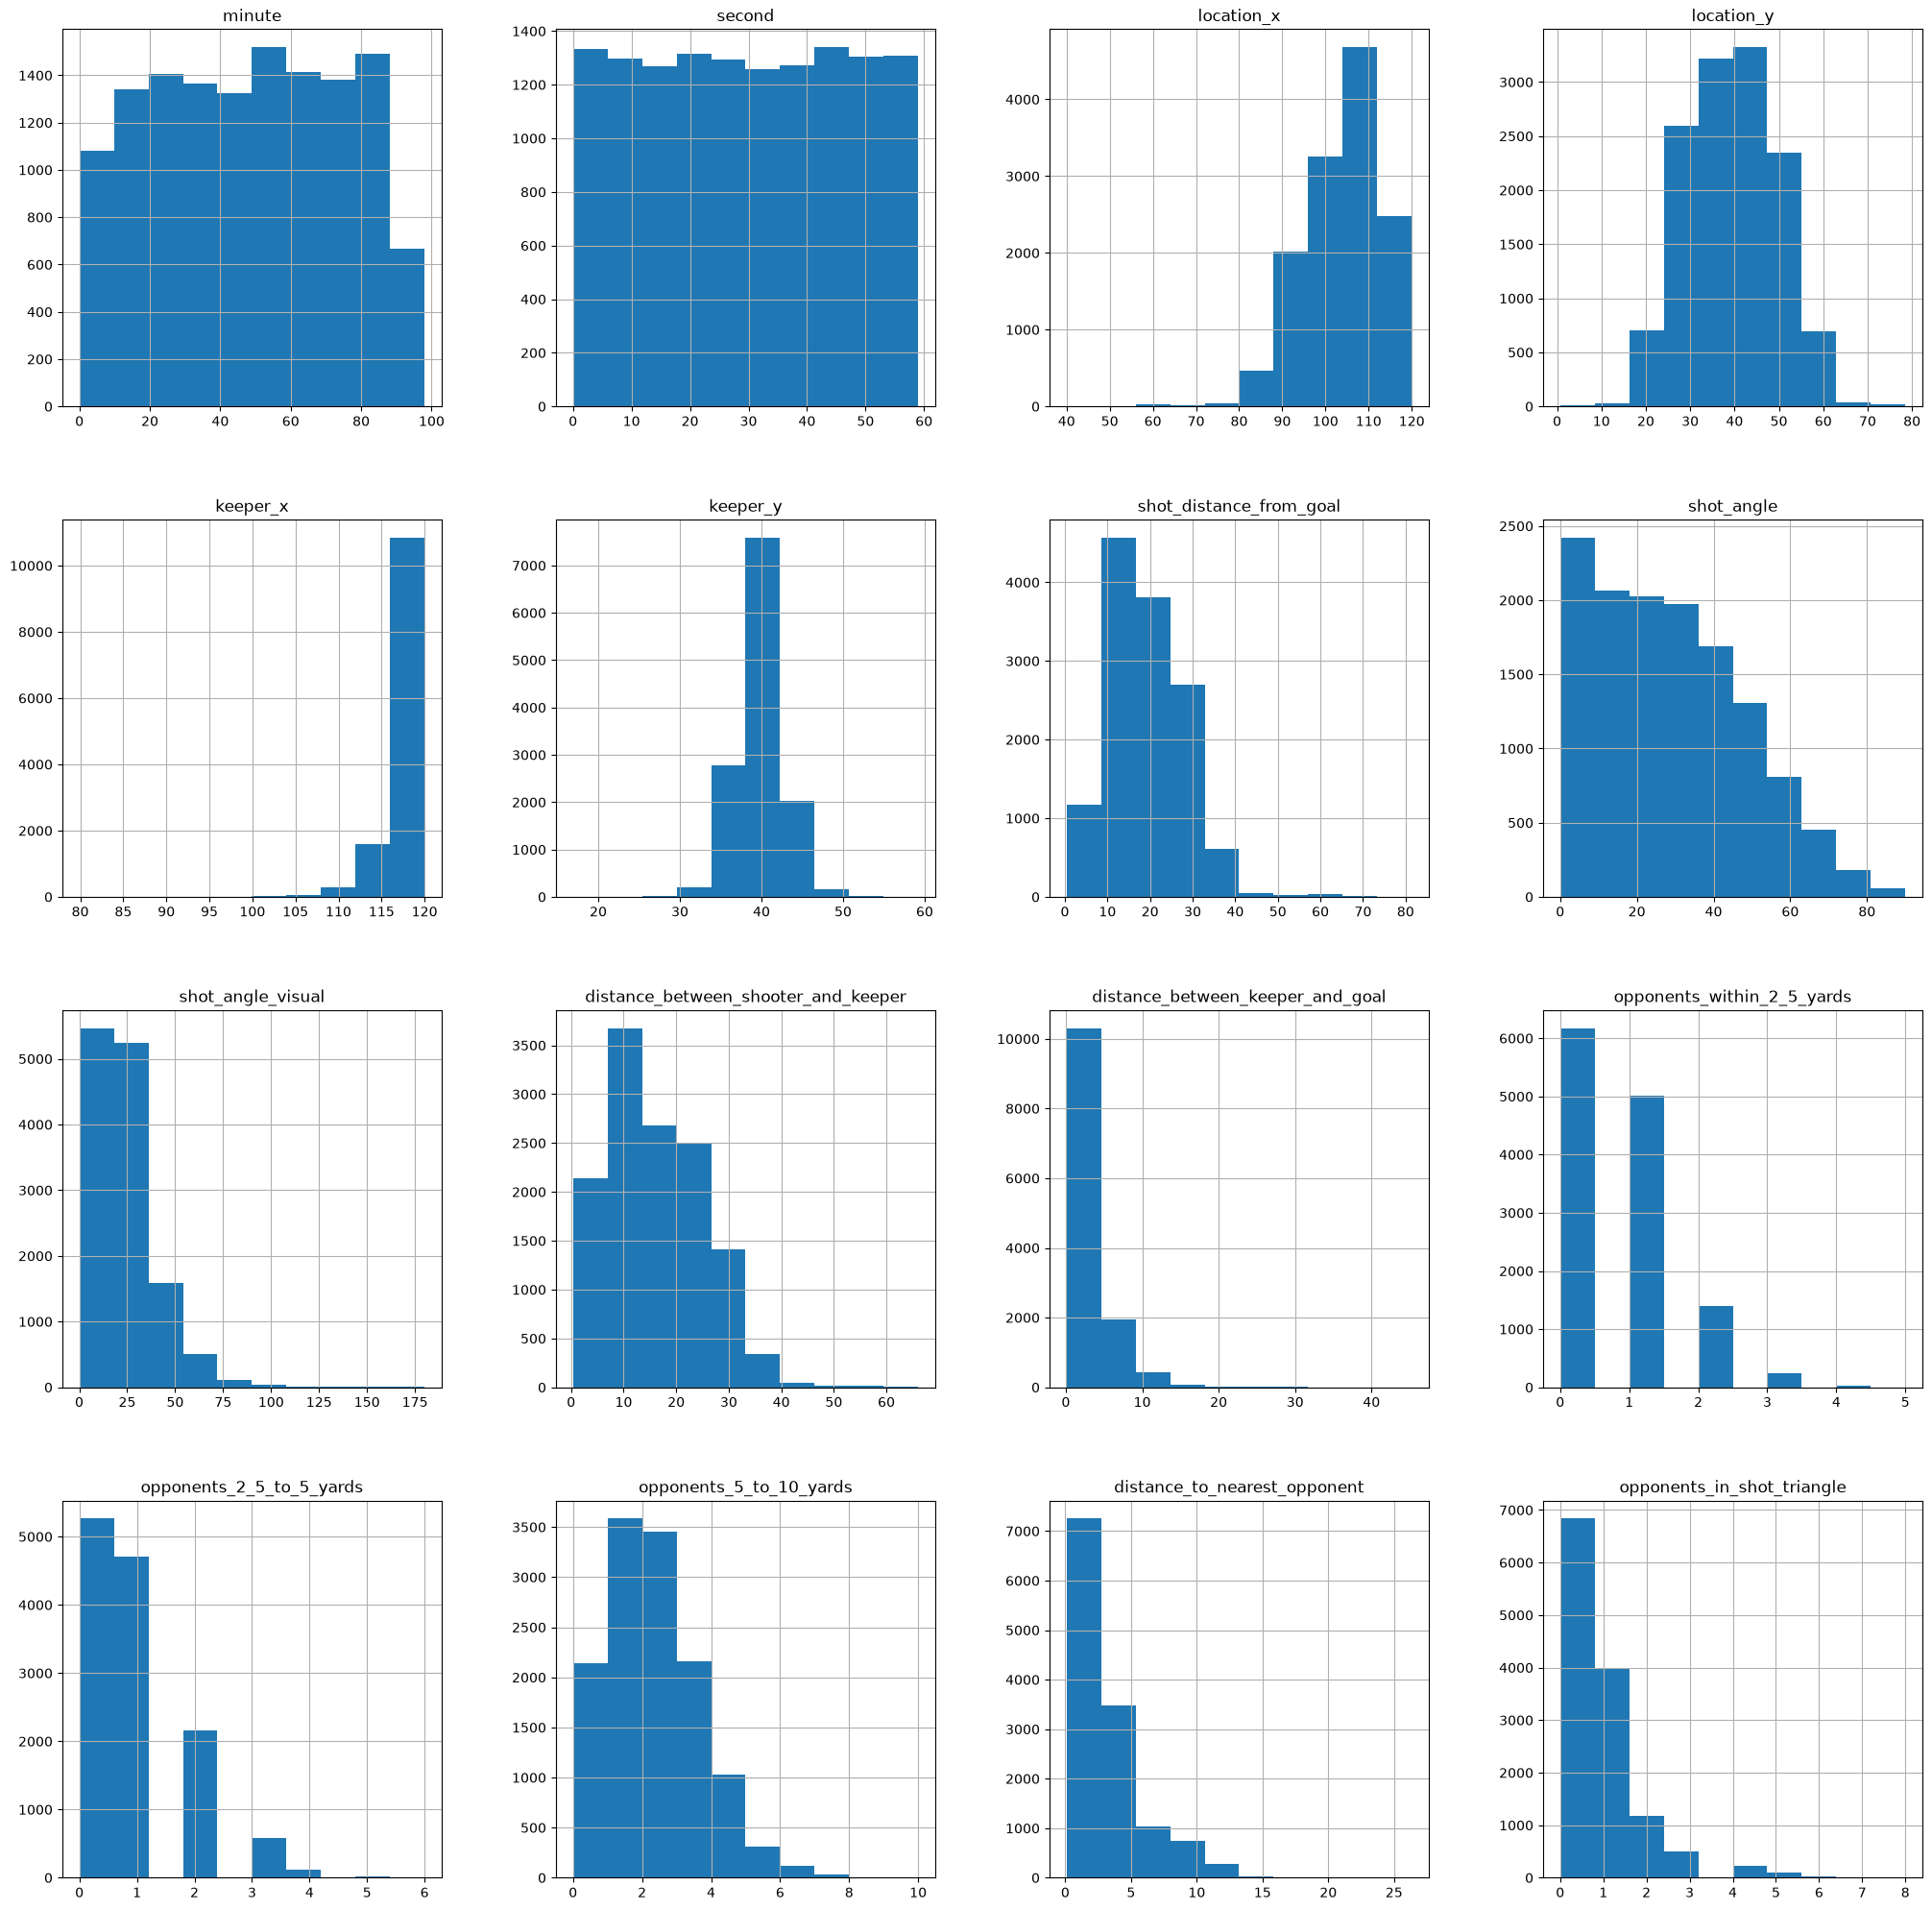

In [69]:
fig, ax = plt.subplots(1, 1 ,figsize=(25,25))
barcelona_shots[numeric_features].hist(ax=ax)

In [72]:
correlation = barcelona_shots[numeric_features].corr()

correlation.style.background_gradient(cmap='coolwarm')

,minute,second,location_x,location_y,keeper_x,keeper_y,shot_distance_from_goal,shot_angle,shot_angle_visual,distance_between_shooter_and_keeper,distance_between_keeper_and_goal,opponents_within_2_5_yards,opponents_2_5_to_5_yards,opponents_5_to_10_yards,distance_to_nearest_opponent,opponents_in_shot_triangle
minute,1.000000,-0.007823,0.011442,0.014537,-0.029107,0.004343,-0.027401,-0.030344,0.012013,-0.030004,0.020838,-0.007511,-0.000346,0.005725,0.010503,0.005264
second,-0.007823,1.000000,-0.003115,0.005800,-0.002839,0.007421,0.000863,-0.000644,-0.001110,-0.000516,0.001042,-0.001928,-0.000542,0.030385,-0.002170,0.000314
location_x,0.011442,-0.003115,1.000000,-0.026784,0.039040,-0.021745,-0.936985,0.484626,0.552238,-0.918633,0.150607,0.314306,0.131719,-0.000137,-0.418783,-0.337751
location_y,0.014537,0.005800,-0.026784,1.000000,-0.025142,0.679842,0.010150,-0.046551,0.019795,0.005373,0.021139,-0.013242,-0.012596,0.002818,0.021792,-0.000676
keeper_x,-0.029107,-0.002839,0.039040,-0.025142,1.000000,0.040278,-0.015129,0.058935,-0.007251,0.228686,-0.897913,0.048498,0.040096,0.135308,0.044835,0.227793
keeper_y,0.004343,0.007421,-0.021745,0.679842,0.040278,1.000000,0.017694,-0.020700,-0.004369,0.024640,-0.041624,-0.018462,-0.012266,0.021891,0.027054,0.012762
shot_distance_from_goal,-0.027401,0.000863,-0.936985,0.010150,-0.015129,0.017694,1.000000,-0.186872,-0.720522,0.955477,-0.089005,-0.349331,-0.176686,-0.076626,0.441549,0.280447
shot_angle,-0.030344,-0.000644,0.484626,-0.046551,0.058935,-0.020700,-0.186872,1.000000,-0.203233,-0.263649,0.234454,0.010827,-0.082622,-0.180715,-0.093949,-0.257829
shot_angle_visual,0.012013,-0.001110,0.552238,0.019795,-0.007251,-0.004369,-0.720522,-0.203233,1.000000,-0.630561,-0.023445,0.279307,0.164022,0.109794,-0.292362,-0.162920
distance_between_shooter_and_keeper,-0.030004,-0.000516,-0.918633,0.005373,0.228686,0.024640,0.955477,-0.263649,-0.630561,1.000000,-0.344647,-0.324549,-0.152588,-0.019748,0.448656,0.354485
